# Camera Pose Calibration From SiPMs

Recovers each camera's real-world pose independent of LAr10Ana's bubble triangulation, by
rendering light sources at the SiPMs' actual 3D positions and
comparing against what the assumed pose (`PoseMatrixEstimation.ipynb`'s
`outputs/estimated_pose_matrices/*.npy`) predicts a real camera would see there.

In [1]:
import os, sys, json
if not os.path.isdir("modules"):
    os.chdir("..")
sys.path.insert(0, "modules")

from utils import *
import pose_calibration as lc
import real_data_loading as rdl

# Cosmetic only: silences Mitsuba's PLYMesh warning about the distorted-jar meshes'
# unused "edge" element (not needed for rendering, from blender).
# Keeps Error-level messages, so real problems still surface.
mi.set_log_level(mi.LogLevel.Error)
# Every figure and render this notebook makes goes into one folder per run:
#   outputs/poseSolve/<date ran>/figures/NN_<name>.png   -- the plots shown inline, in notebook order
#   outputs/poseSolve/<date ran>/renders/<pose>/...png   -- the raw Mitsuba renders behind them
poseSolveDir = pathlib.Path("outputs/poseSolve") / time.strftime("%Y_%m_%d_%H_%M_%S")
print("saving this run's images to", poseSolveDir)

def save_figure(fig, name):
    figPath = poseSolveDir / "figures" / f"{name}.png"
    figPath.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figPath, dpi=150, bbox_inches="tight")
    print("saved figure:", figPath)

def save_render(image, name, isDiff=False):
    """Saves a mono render as an 8-bit PNG: gamma 2.2 for a plain render, or scaled to
    its own max for a diff image (so a faint marker still shows)."""
    renderPath = poseSolveDir / "renders" / f"{name}.png"
    renderPath.parent.mkdir(parents=True, exist_ok=True)
    image = np.asarray(image, dtype=float)
    if isDiff:
        image = np.clip(image / max(image.max(), 1e-9), 0, 1)
    else:
        image = np.clip(image, 0, 1) ** (1 / 2.2)
    plt.imsave(renderPath, image, cmap="gray", vmin=0, vmax=1)
    print("saved render:", renderPath)

saving this run's images to outputs/poseSolve/2026_11_09_09_25_41


In [2]:
positions = lc.load_sipm_fiducial_positions()

print(f"{len(positions['fiducial'])} fiducial markers, {len(positions['sipm'])} SiPMs")
for markerId, pos in positions["fiducial"].items():
    print(f"  fiducial {markerId}: {pos} cm")

5 fiducial markers, 48 SiPMs
  fiducial 1: [-5.30300001  2.23937179  0.        ] cm
  fiducial 2: [-2.23817626  5.30375772  0.        ] cm
  fiducial 3: [ 5.30300001 -2.23937179  0.        ] cm
  fiducial 4: [ 2.23817626 -5.30375772  0.        ] cm
  fiducial 5: [0. 0. 0.] cm


In [3]:
camera = 2

## Rendering light sources at the actual SiPM positions

Instead of trying to detect SiPM covers or fiducial markers in a real photo,
place a small light source at each SiPM's *actual* 3D position and render the scene for real.
This shows what the camera would really see there -- whether each one is directly visible, hidden behind the copper
panel, or (like the LED rings) only visible via reflection off the curved dome -- since
it's an actual physically-traced render of this scene's real geometry, not a flat 2D
projection.

saved render: outputs/poseSolve/2026_11_09_09_25_41/renders/cam2_assumed_pose/all_sipms_lit.png
saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/01_cam2_assumed_pose_all_sipms_lit.png


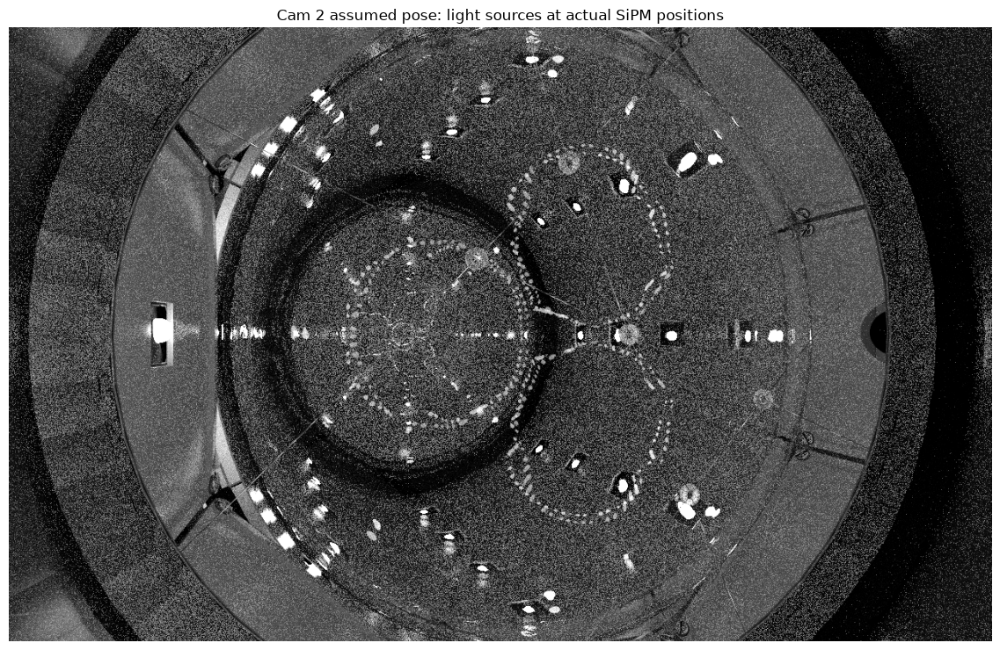

In [4]:
lightMaterials = create_materials(with_fluids=True)
lightComponents = load_components(materials=lightMaterials, use_distorted_jar=True)
lc.add_point_light_markers(lightComponents, positions["sipm"])

lightSensor = create_sensor(sensor_number=camera, sample_count=512)
lightScene = load_scene(components=lightComponents, sensor=lightSensor)
sipmLightImage = to_mono(np.array(render(scene=lightScene, denoise=False)))

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(np.clip(sipmLightImage, 0, 1) ** (1 / 2.2), cmap='gray')
ax.set_title(f"Cam {camera} assumed pose: light sources at actual SiPM positions")
ax.axis('off')
fig.tight_layout()

save_render(sipmLightImage, f"cam{camera}_assumed_pose/all_sipms_lit")
save_figure(fig, f"01_cam{camera}_assumed_pose_all_sipms_lit")

saved render: outputs/poseSolve/2026_11_09_09_25_41/renders/cam2_assumed_pose/baseline_no_markers.png
saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/02_cam2_assumed_pose_baseline.png


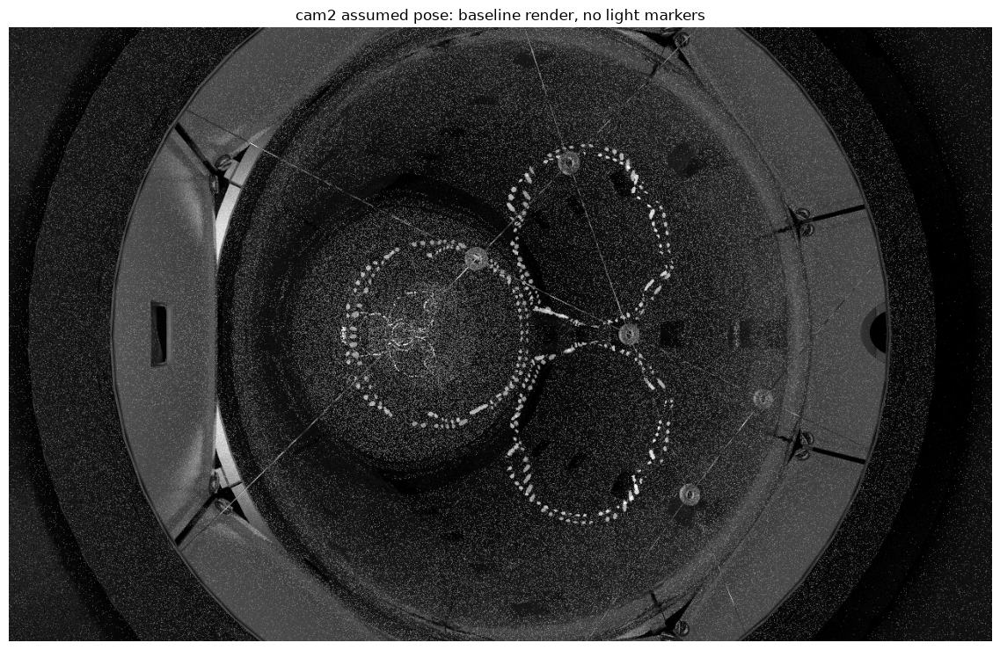

In [5]:
# Same scene/sensor, just no SiPM lights to act as a background to subtract from.
baselineMaterials = create_materials(with_fluids=True)
baselineComponents = load_components(materials=baselineMaterials, use_distorted_jar=True)
baselineSensor = create_sensor(sensor_number=camera, sample_count=512)
baselineScene = load_scene(components=baselineComponents, sensor=baselineSensor)
baselineImage = to_mono(np.array(render(scene=baselineScene, denoise=False)))

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(np.clip(baselineImage, 0, 1) ** (1 / 2.2), cmap='gray')
ax.set_title(f"cam{camera} assumed pose: baseline render, no light markers")
ax.axis('off')
fig.tight_layout()
save_render(baselineImage, f"cam{camera}_assumed_pose/baseline_no_markers")
save_figure(fig, f"02_cam{camera}_assumed_pose_baseline")

## Finding the rendered light sources

Now try to find those same light markers back out of the render itself, with
`detect_light_markers()` -- the same question a detector will eventually have to
answer for a *real* photo, but here against a render where the ground truth (there
should be one blob per SiPM, right where `add_point_light_markers()` put it) is known,
so it's a sanity check on the detector itself before pointing it at real data.

found 36 candidate light markers (expected up to 48)
saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/03_cam2_detected_light_markers.png


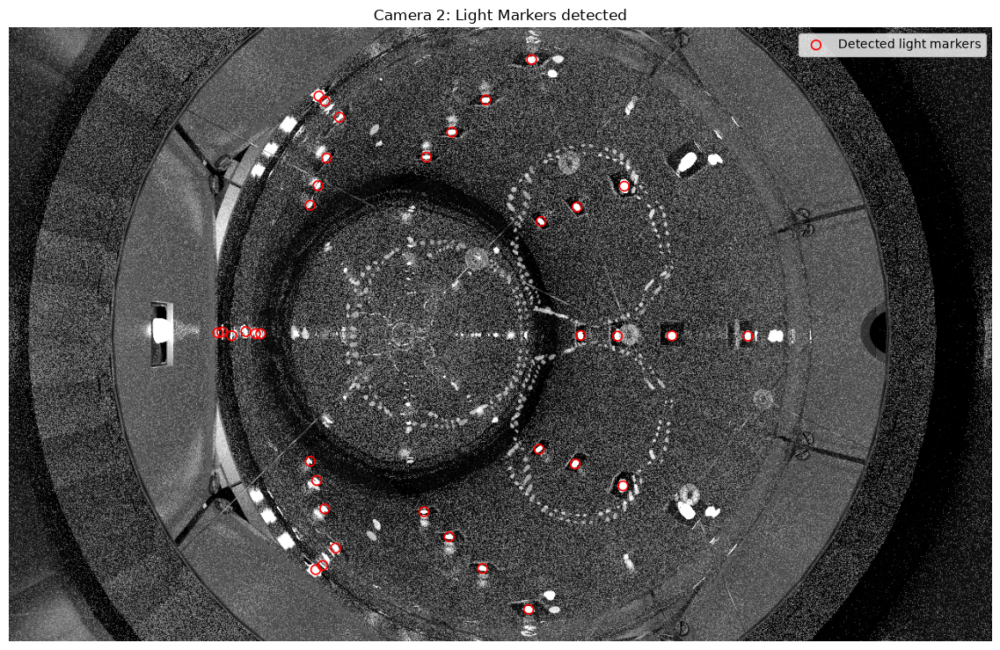

In [6]:
detectedPixels = lc.detect_light_markers(sipmLightImage, baseline=baselineImage)
print(f"found {len(detectedPixels)} candidate light markers "
      f"(expected up to {len(positions['sipm'])})")

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(np.clip(sipmLightImage, 0, 1) ** (1 / 2.2), cmap='gray')
ax.scatter(detectedPixels[:, 0], detectedPixels[:, 1], s=60, facecolors='none',
           edgecolors='red', linewidths=1.2, label='Detected light markers')
ax.legend(loc='upper right')
ax.set_title(f"Camera {camera}: Light Markers detected")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"03_cam{camera}_detected_light_markers")

## Comparing against a real photo

`project_positions_to_pixels()`'s flat projection isn't refraction-aware -- checked:
diffing a single-marker render against a no-marker baseline showed the marker's actual
rendered pixel drifting 15-70px from that flat projection, growing with distance from the
image center, and dropping to ~5px once removing the liquid argon (no refraction) is
tested instead. So the flat projection isn't a reliable stand-in for where a real photo
would show a SiPM either, and matching against it (as an earlier version of this notebook
did) mostly just checks that detection and projection math agree with each other, not
that the assumed pose matches reality.

`detectedPixels` (above) doesn't have that problem -- it comes from an actual ray-traced
render, so refraction through the jar/fluid is already correctly baked in for the
*assumed* pose. The real test of whether that assumed pose matches the *real* camera is
whether those same pixel positions line up with a real photo from the same camera: if the
assumed pose is right, wherever a SiPM shows up in the render should land close to where it
actually shows up in reality. No real-photo SiPM detector is trusted yet (see
`detect_sipm_covers()`'s own docstring), so for now this is a visual overlay rather than an
automated match.

saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/04_cam2_real_photo_vs_assumed_render.png


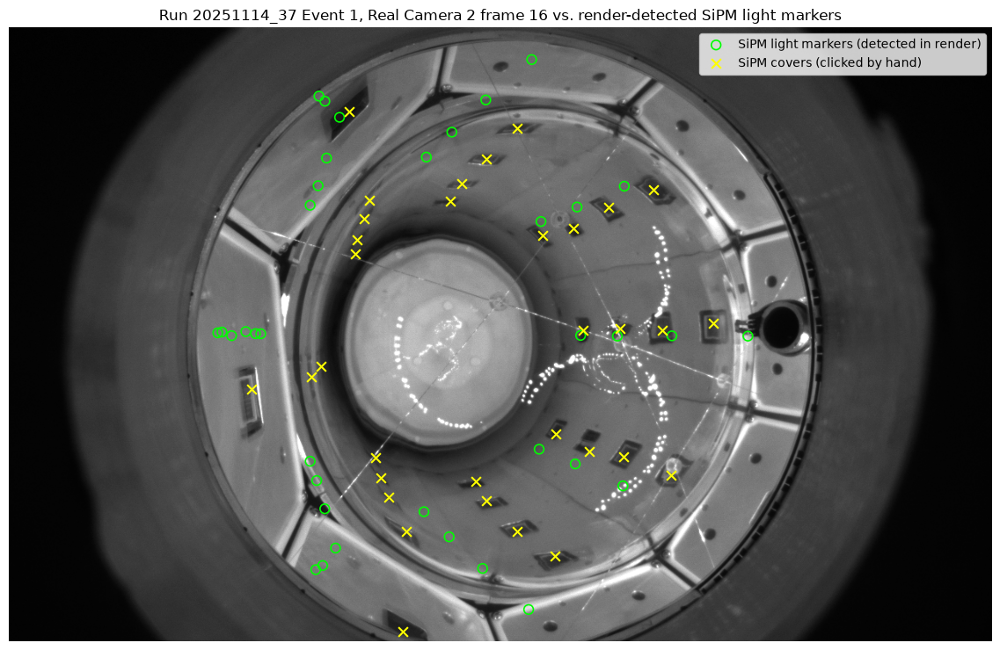

In [7]:
run_name = "20251114_37"
run_dir = rdl.RUN_DIRS[run_name]
ev = rdl.single_bubble_events(run_dir)[0]
frame = 16

realImage = load_image(rdl.camera_image_path(run_dir, ev, camera, frame))

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(detectedPixels[:, 0], detectedPixels[:, 1], s=60, facecolors='none',
           edgecolors='lime', linewidths=1.2,
           label='SiPM light markers (detected in render)')

# Overlay clicked points (scripts/click_label_points.py), if you've made any,
# for a direct by-eye comparison against the render-detected positions above.
clickedPointsPath = "outputs/clicked_points/cam2-img16.json"
if os.path.exists(clickedPointsPath):
    clickedPixels = lc.load_clicked_points(clickedPointsPath)
    ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
               linewidths=1.5, label='SiPM covers (clicked by hand)')
else:
    print(f"no clicked points found at {clickedPointsPath} -- run "
          f"scripts/click_label_points.py to add some")

ax.legend(loc='upper right')
ax.set_title(f"Run {run_name} Event {ev}, Real Camera {camera} frame {frame} "
             f"vs. render-detected SiPM light markers")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"04_cam{camera}_real_photo_vs_assumed_render")

## Labeling each visible SiPM's true render position

To match your clicked covers (`scripts/click_label_points.py`) to a specific SiPM id,
we need an id-labeled *render* position for each one -- not `project_positions_to_pixels()`
(refraction-biased by tens of pixels) and not `detectedPixels` above
(all 48 lit at once, so close-together SiPMs like ring 4's can merge into one blob).

Instead this renders each SiPM's marker **alone** and diffs against the same
`baselineImage` from above -- the same approach that pinned down SiPM 46 earlier, just
run for every id. A higher radiance (200 vs. the usual 80) keeps the peak unambiguous
even at a modest sample count. Slow -- one full render per SiPM, ~15-20s each, so
~48 x that -- and prints progress as it goes. Anything whose peak diff stays near noise
level (<10, same cutoff `detect_light_markers()` uses) isn't directly visible from this
camera and gets skipped, same as the occluded ones we already found by ring.

In [8]:
# Cached: this loop is ~12-15 min. Delete the cache file to force a re-render (only a
# re-render saves the 48 single-SiPM renders into this run's renders/ folder).
sipmRenderPositionsPath = f"outputs/pose_calibration/cam{camera}_sipm_render_positions.json"

if os.path.exists(sipmRenderPositionsPath):
    with open(sipmRenderPositionsPath) as f:
        sipmRenderPositions = {sid: np.array(xy) for sid, xy in json.load(f).items()}
    print(f"loaded {len(sipmRenderPositions)} cached SiPM render positions from {sipmRenderPositionsPath}")
else:
    sipmRenderPositions = {}
    visibilityThreshold = 10.0

    for i, (sid, pos) in enumerate(positions["sipm"].items()):
        perIdMaterials = create_materials(with_fluids=True)
        perIdComponents = load_components(materials=perIdMaterials, use_distorted_jar=True)
        lc.add_point_light_markers(perIdComponents, {sid: pos}, radiance=200.0)
        perIdSensor = create_sensor(sensor_number=camera, sample_count=64)
        perIdScene = load_scene(components=perIdComponents, sensor=perIdSensor)
        perIdImage = to_mono(np.array(render(scene=perIdScene, denoise=False)))

        diff = perIdImage - baselineImage
        save_render(perIdImage, f"cam{camera}_assumed_pose/single_sipm/sipm_{sid}")
        save_render(diff, f"cam{camera}_assumed_pose/single_sipm/sipm_{sid}_diff", isDiff=True)
        maxDiff = diff.max()
        yx = np.unravel_index(np.argmax(diff), diff.shape)
        peak = np.array([yx[1], yx[0]])
        visible = maxDiff >= visibilityThreshold
        if visible:
            sipmRenderPositions[sid] = peak

        status = "" if visible else " (not visible, skipped)"
        print(f"[{i + 1}/{len(positions['sipm'])}] sipm {sid}: maxDiff={maxDiff:.1f} "
              f"peak={tuple(peak)}{status}")

    print(f"\n{len(sipmRenderPositions)}/{len(positions['sipm'])} SiPMs visible from cam{camera}")

    os.makedirs(os.path.dirname(sipmRenderPositionsPath), exist_ok=True)
    with open(sipmRenderPositionsPath, "w") as f:
        json.dump({sid: [int(v) for v in xy] for sid, xy in sipmRenderPositions.items()}, f, indent=1)

loaded 36 cached SiPM render positions from outputs/pose_calibration/cam2_sipm_render_positions.json


### Example: one single-SiPM render

The loop above only keeps each id's peak pixel and discards the actual image (48 full
renders would be a lot of memory to hold onto at once). Here's what one of those
individual renders -- and the diff that finds its peak -- actually looks like, using
SiPM 46 (the one we already identified as the rectangular cover earlier in this
notebook) as the example.

SiPM 46: maxDiff=126.2, peak=(209, 396)
saved render: outputs/poseSolve/2026_11_09_09_25_41/renders/cam2_assumed_pose/single_sipm/sipm_46.png
saved render: outputs/poseSolve/2026_11_09_09_25_41/renders/cam2_assumed_pose/single_sipm/sipm_46_diff.png
saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/05_cam2_single_sipm_46_example.png


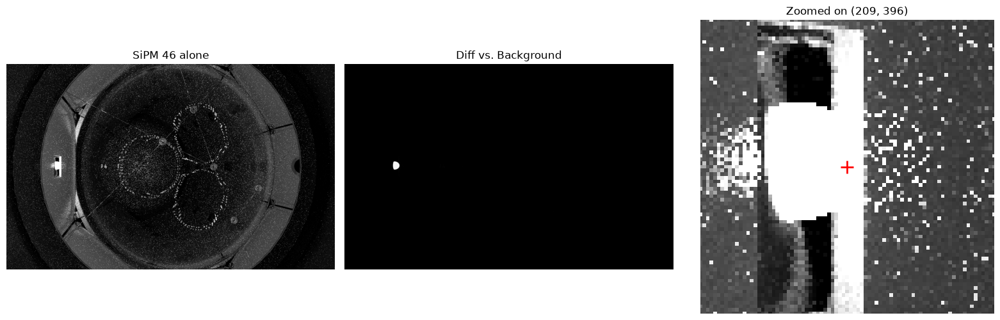

In [9]:
exampleId = "46"

exampleMaterials = create_materials(with_fluids=True)
exampleComponents = load_components(materials=exampleMaterials, use_distorted_jar=True)
lc.add_point_light_markers(exampleComponents, {exampleId: positions["sipm"][exampleId]}, radiance=200.0)
exampleSensor = create_sensor(sensor_number=camera, sample_count=64)
exampleScene = load_scene(components=exampleComponents, sensor=exampleSensor)
exampleImage = to_mono(np.array(render(scene=exampleScene, denoise=False)))

exampleDiff = exampleImage - baselineImage
yx = np.unravel_index(np.argmax(exampleDiff), exampleDiff.shape)
examplePeak = (int(yx[1]), int(yx[0]))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(np.clip(exampleImage, 0, 1) ** (1 / 2.2), cmap='gray')
axes[0].set_title(f"SiPM {exampleId} alone")
axes[1].imshow(exampleDiff, cmap='gray', vmin=0, vmax=exampleDiff.max())
axes[1].set_title("Diff vs. Background")
win = 40
x0, x1 = max(examplePeak[0] - win, 0), examplePeak[0] + win
y0, y1 = max(examplePeak[1] - win, 0), examplePeak[1] + win
axes[2].imshow(np.clip(exampleImage, 0, 1) ** (1 / 2.2), cmap='gray')
axes[2].plot(*examplePeak, '+', color='red', markersize=15, markeredgewidth=2)
axes[2].set_xlim(x0, x1)
axes[2].set_ylim(y1, y0)
axes[2].set_title(f"Zoomed on {examplePeak}")
for ax in axes:
    ax.axis('off')
fig.tight_layout()
print(f"SiPM {exampleId}: maxDiff={exampleDiff.max():.1f}, peak={examplePeak}")
save_render(exampleImage, f"cam{camera}_assumed_pose/single_sipm/sipm_{exampleId}")
save_render(exampleDiff, f"cam{camera}_assumed_pose/single_sipm/sipm_{exampleId}_diff", isDiff=True)
save_figure(fig, f"05_cam{camera}_single_sipm_{exampleId}_example")

## Matching manually found covers to SiPM ids

Nearest-neighbor match each clicked point against `sipmRenderPositions` above (id-labeled,
refraction-correct render positions) within `maxMatchDistancePx`. Reports which id each
click matched to, and flags anything left over on either side.

matched 7/33 clicked points to a SiPM id (within 30px)
  click 2 ([734.7 261.6]) -> sipm 73, 28.9px away
  click 3 ([694.5 270.3]) -> sipm 72, 21.6px away
  click 26 ([754.8 552.5]) -> sipm 13, 25.7px away
  click 27 ([711.2 529. ]) -> sipm 12, 27.8px away
  click 29 ([850.  394.3]) -> sipm 84, 18.2px away
  click 30 ([795.  391.6]) -> sipm 83, 10.6px away
  click 31 ([746.7 394.3]) -> sipm 82, 5.0px away

26 clicked point(s) didn't match any visible SiPM: [0, 1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 28, 32]
saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/06_cam2_clicks_nearest_neighbor_matches.png


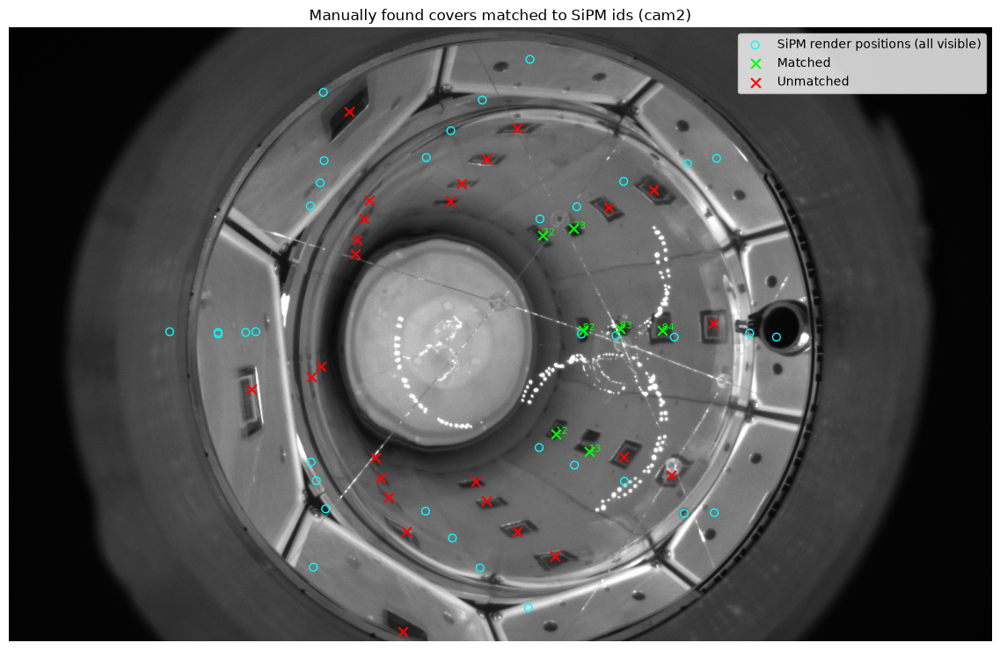

In [10]:
clickedPointsPath = "outputs/clicked_points/cam2-img16.json"
maxMatchDistancePx = 30

if not os.path.exists(clickedPointsPath):
    print(f"no clicked points found at {clickedPointsPath}")
else:
    clickedPixels = lc.load_clicked_points(clickedPointsPath)
    sipmIds = list(sipmRenderPositions.keys())
    sipmXY = np.array(list(sipmRenderPositions.values()))

    matches = []
    for i, click in enumerate(clickedPixels):
        distances = np.linalg.norm(sipmXY - click, axis=1)
        nearest = distances.argmin()
        if distances[nearest] <= maxMatchDistancePx:
            matches.append((i, sipmIds[nearest], distances[nearest]))
    matchedClickIndices = {m[0] for m in matches}

    print(f"matched {len(matches)}/{len(clickedPixels)} clicked points to a SiPM id "
          f"(within {maxMatchDistancePx}px)")
    for i, sid, dist in matches:
        print(f"  click {i} ({clickedPixels[i].round(1)}) -> sipm {sid}, {dist:.1f}px away")

    unmatchedClicks = [i for i in range(len(clickedPixels)) if i not in matchedClickIndices]
    if unmatchedClicks:
        print(f"\n{len(unmatchedClicks)} clicked point(s) didn't match any visible SiPM: "
              f"{unmatchedClicks}")

    realImage = load_image(rdl.camera_image_path(run_dir, ev, camera, frame))
    fig, ax = plt.subplots(figsize=(12, 7.5))
    ax.imshow(realImage, cmap='gray')
    ax.scatter(sipmXY[:, 0], sipmXY[:, 1], s=40, facecolors='none', edgecolors='cyan',
               linewidths=1, label='SiPM render positions (all visible)')
    if matchedClickIndices:
        matchedXY = clickedPixels[list(matchedClickIndices)]
        ax.scatter(matchedXY[:, 0], matchedXY[:, 1], s=60, marker='x', color='lime',
                   linewidths=1.5, label='Matched')
    if unmatchedClicks:
        unmatchedXY = clickedPixels[unmatchedClicks]
        ax.scatter(unmatchedXY[:, 0], unmatchedXY[:, 1], s=60, marker='x', color='red',
                   linewidths=1.5, label='Unmatched')
    for i, sid, dist in matches:
        ax.annotate(sid, clickedPixels[i], color='lime', fontsize=8)
    ax.legend(loc='upper right')
    ax.set_title(f"Manually found covers matched to SiPM ids (cam{camera})")
    ax.axis('off')
    fig.tight_layout()
    save_figure(fig, f"06_cam{camera}_clicks_nearest_neighbor_matches")

## Visualizing the offset

For every clicked cover, draw an arrow to its *nearest* SiPM render position --
regardless of `maxMatchDistancePx` -- so the direction and size of the mismatch is
visible even for clicks that didn't technically "match". Green arrows are within the
cutoff (same as the matches above); red arrows are the rest, and their length is a
direct read on how far off the assumed pose is at that point in the frame.

nearest-SiPM distance per click: min=5.0px median=58.7px max=130.3px
saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/07_cam2_click_offsets_assumed_pose.png


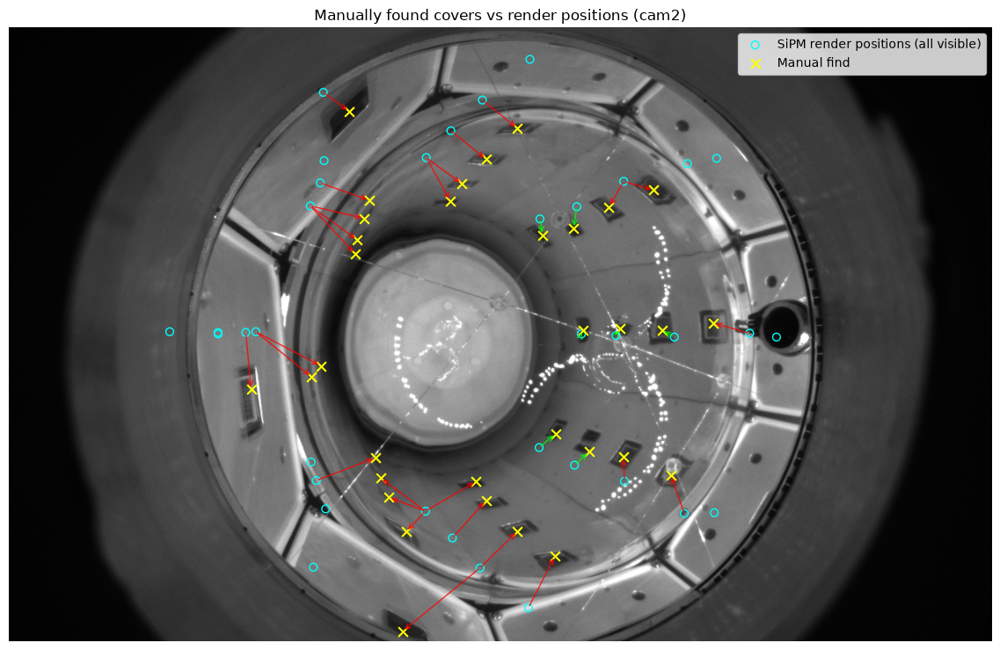

In [11]:
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(sipmXY[:, 0], sipmXY[:, 1], s=40, facecolors='none', edgecolors='cyan',
           linewidths=1, label='SiPM render positions (all visible)')
ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
           linewidths=1.5, label='Manual find')

offsetDistances = []
for click in clickedPixels:
    distances = np.linalg.norm(sipmXY - click, axis=1)
    nearest = distances.argmin()
    offsetDistances.append(distances[nearest])
    color = 'lime' if distances[nearest] <= maxMatchDistancePx else 'red'
    ax.annotate('', xy=sipmXY[nearest], xytext=click,
                arrowprops=dict(arrowstyle='<-', color=color, linewidth=1, alpha=0.8))

offsetDistances = np.array(offsetDistances)
print(f"nearest-SiPM distance per click: min={offsetDistances.min():.1f}px "
      f"median={np.median(offsetDistances):.1f}px max={offsetDistances.max():.1f}px")

ax.legend(loc='upper right')
ax.set_title(f"Manually found covers vs render positions (cam{camera})")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"07_cam{camera}_click_offsets_assumed_pose")

## Solving for the real pose

The arrows above are far too long and too consistent in direction to be noise: the
assumed pose itself is off. `lc.fit_pose_correction()` solves for the correction:

- **Refraction**: each SiPM's refraction offset is measured once from its own
  render (`sipmRenderPositions` minus the flat projection) and assumed to stay fixed
  for a small pose change. Prediction = flat projection at the corrected pose + offset.
- **Correspondence**: ICP-style. Match clicks to predictions one-to-one within a
  cutoff, fit, shrink the cutoff (130 -> 90 -> 60 -> 40px), and repeat.
- **Rotation only** (camera pivots about its own center). Also solving for translation
  fit the clicks better on paper, but it did so with a 2-3cm camera shift. A render at
  that pose put the camera inside the viewport geometry, and only 14 of 36 SiPMs stayed
  visible. So the extra freedom was absorbing something the flat model leaves out
  (most likely lens distortion or fov), not a real offset.

In [12]:
sipmIds = list(sipmRenderPositions.keys())
assumedToWorld = np.array(create_sensor(sensor_number=camera)["to_world"].matrix)

poseFit = lc.fit_pose_correction(
    worldPositionsCm=[positions["sipm"][sid] for sid in sipmIds],
    renderPixels=[sipmRenderPositions[sid] for sid in sipmIds],
    observedPixels=clickedPixels,
    toWorld=assumedToWorld,
)
correctedToWorld = poseFit["toWorld"]

rotationDeg = np.rad2deg(poseFit["correction"][:3])
print(f"cam{camera} rotation correction (camera frame, Rodrigues): {rotationDeg.round(2)} deg "
      f"-> {np.linalg.norm(rotationDeg):.2f} deg total")
print(f"matched {len(poseFit['pairs'])}/{len(clickedPixels)} clicks one-to-one; predicted residual "
      f"median {np.median(poseFit['residualsPx']):.1f}px, max {poseFit['residualsPx'].max():.1f}px "
      f"(was {np.median(offsetDistances):.1f}px median before)")
print("matched SiPM ids:", sorted(sipmIds[p] for p, _ in poseFit["pairs"]))

cam2 rotation correction (camera frame, Rodrigues): [-1.02  5.09  6.46] deg -> 8.29 deg total
matched 24/33 clicks one-to-one; predicted residual median 15.9px, max 30.8px (was 58.7px median before)
matched SiPM ids: ['12', '13', '14', '22', '23', '24', '32', '33', '34', '44', '45', '52', '53', '54', '55', '62', '63', '64', '72', '73', '74', '82', '83', '84']


saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/08_cam2_corrected_pose_prediction.png


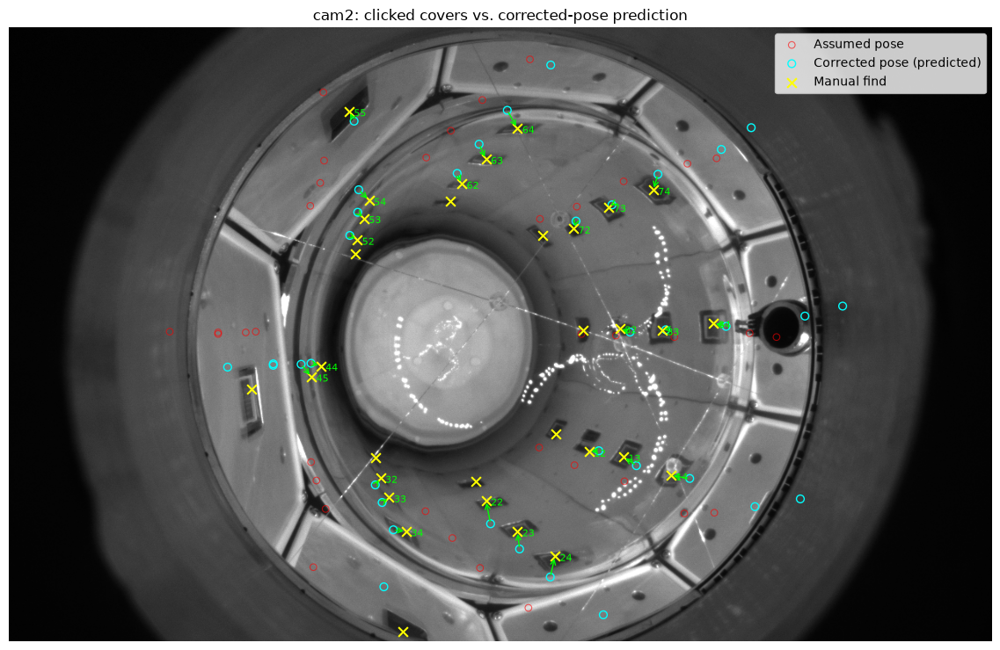

In [13]:
predictedPixels = (lc.flat_project(correctedToWorld, [positions["sipm"][sid] for sid in sipmIds])
                   + poseFit["deltaPx"])

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(sipmXY[:, 0], sipmXY[:, 1], s=30, facecolors='none', edgecolors='red', linewidths=0.8,
           alpha=0.6, label='Assumed pose')
ax.scatter(predictedPixels[:, 0], predictedPixels[:, 1], s=40, facecolors='none', edgecolors='cyan',
           linewidths=1, label='Corrected pose (predicted)')
ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
           linewidths=1.5, label='Manual find')
for p, o in poseFit["pairs"]:
    ax.annotate('', xy=predictedPixels[p], xytext=clickedPixels[o],
                arrowprops=dict(arrowstyle='<-', color='lime', linewidth=1))
    ax.annotate(sipmIds[p], clickedPixels[o], color='lime', fontsize=8, xytext=(4, -4),
                textcoords='offset points')
ax.legend(loc='upper right')
ax.set_title(f"cam{camera}: clicked covers vs. corrected-pose prediction")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"08_cam{camera}_corrected_pose_prediction")

### Checking the corrected pose with a real render

The prediction above relies on the fixed-refraction assumption. To check it, render all
SiPM light markers from `correctedToWorld` and see where they actually land. On cam2 this
matched the prediction: about 57px median before, about 15px after. Re-measuring the
refraction offsets at the new pose and refitting moved the camera by less than 0.6deg,
so one pass is enough. The remaining ~15px is probably lens distortion, which neither
the renderer nor this fit models.

saved render: outputs/poseSolve/2026_11_09_09_25_41/renders/cam2_corrected_pose/all_sipms_lit.png
saved render: outputs/poseSolve/2026_11_09_09_25_41/renders/cam2_corrected_pose/baseline_no_markers.png
36 light markers visible from the corrected pose
matched clicks -> nearest rendered marker: assumed pose median 56.0px, corrected pose median 14.4px (max 33.8px)
saved figure: outputs/poseSolve/2026_11_09_09_25_41/figures/09_cam2_real_photo_vs_corrected_render.png
saved corrected to_world to outputs/pose_calibration/cam2_corrected_to_world.npy


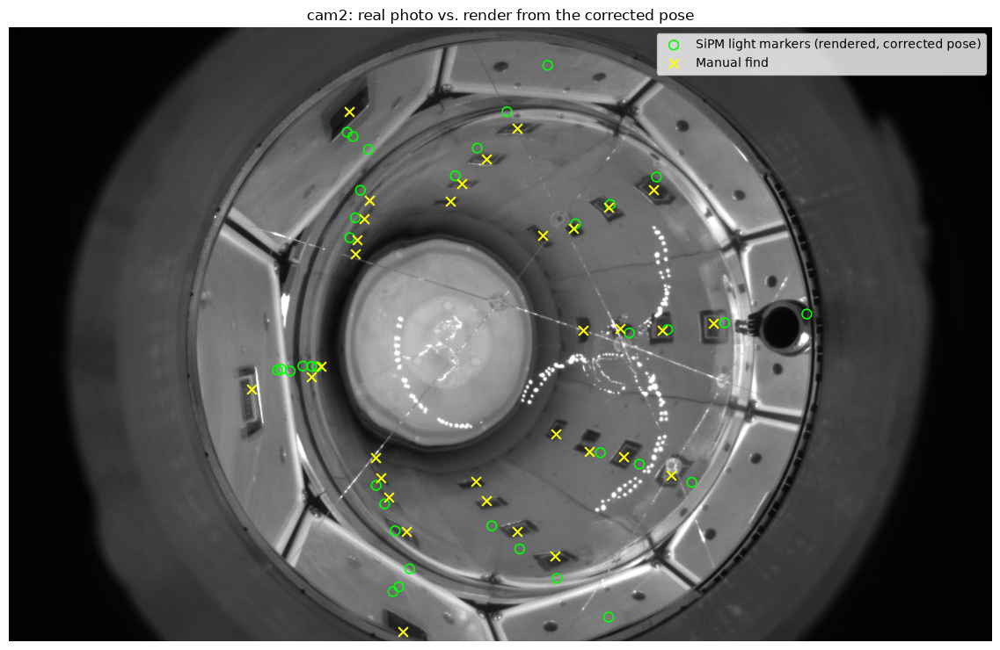

In [14]:
correctedLit, correctedBaseline = lc.render_light_marker_pair(camera, positions["sipm"],
                                                              toWorld=correctedToWorld)
save_render(correctedLit, f"cam{camera}_corrected_pose/all_sipms_lit")
save_render(correctedBaseline, f"cam{camera}_corrected_pose/baseline_no_markers")
correctedDetected = lc.detect_light_markers(correctedLit, baseline=correctedBaseline)

matchedClicks = clickedPixels[[o for _, o in poseFit["pairs"]]]
renderedResidual = np.array([np.linalg.norm(correctedDetected - c, axis=1).min() for c in matchedClicks])
assumedResidual = np.array([np.linalg.norm(detectedPixels - c, axis=1).min() for c in matchedClicks])
print(f"{len(correctedDetected)} light markers visible from the corrected pose")
print(f"matched clicks -> nearest rendered marker: assumed pose median {np.median(assumedResidual):.1f}px, "
      f"corrected pose median {np.median(renderedResidual):.1f}px (max {renderedResidual.max():.1f}px)")

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(correctedDetected[:, 0], correctedDetected[:, 1], s=60, facecolors='none',
           edgecolors='lime', linewidths=1.2, label='SiPM light markers (rendered, corrected pose)')
ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
           linewidths=1.5, label='Manual find')
ax.legend(loc='upper right')
ax.set_title(f"cam{camera}: real photo vs. render from the corrected pose")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"09_cam{camera}_real_photo_vs_corrected_render")

correctedPosePath = f"outputs/pose_calibration/cam{camera}_corrected_to_world.npy"
np.save(correctedPosePath, correctedToWorld)
print(f"saved corrected to_world to {correctedPosePath}")
np.save(poseSolveDir / f"cam{camera}_corrected_to_world.npy", correctedToWorld)

In [15]:
# Everything this run saved, as a tree.
def print_tree(root, indent=""):
    entries = sorted(root.iterdir(), key=lambda p: (p.is_file(), p.name))
    for k, entry in enumerate(entries):
        branch = "└── " if k == len(entries) - 1 else "├── "
        print(indent + branch + entry.name + ("/" if entry.is_dir() else ""))
        if entry.is_dir():
            print_tree(entry, indent + ("    " if k == len(entries) - 1 else "│   "))

print(f"{poseSolveDir}/")
print_tree(poseSolveDir)

outputs/poseSolve/2026_11_09_09_25_41/
├── figures/
│   ├── 01_cam2_assumed_pose_all_sipms_lit.png
│   ├── 02_cam2_assumed_pose_baseline.png
│   ├── 03_cam2_detected_light_markers.png
│   ├── 04_cam2_real_photo_vs_assumed_render.png
│   ├── 05_cam2_single_sipm_46_example.png
│   ├── 06_cam2_clicks_nearest_neighbor_matches.png
│   ├── 07_cam2_click_offsets_assumed_pose.png
│   ├── 08_cam2_corrected_pose_prediction.png
│   └── 09_cam2_real_photo_vs_corrected_render.png
├── renders/
│   ├── cam2_assumed_pose/
│   │   ├── single_sipm/
│   │   │   ├── sipm_46.png
│   │   │   └── sipm_46_diff.png
│   │   ├── all_sipms_lit.png
│   │   └── baseline_no_markers.png
│   └── cam2_corrected_pose/
│       ├── all_sipms_lit.png
│       └── baseline_no_markers.png
└── cam2_corrected_to_world.npy
